In [1]:
import sys
import numpy as np
import pandas as pd
import geopandas as gpd
import shapely
from typing import Callable
import warnings

from quetzal.io import excel
from scipy import sparse
from scipy.spatial.distance import cdist

sys.path.insert(0, r'../../../quetzal')
from quetzal.model import connectionscanmodel, stepmodel

In [2]:
qpath = r'../../'
ipath = qpath + r'inputs/'
var = excel.read_var(ipath + r'parameters.xlsx', scenario='base')

Index(['description', 'unit', 'category', 'parameter', 'base',
       'base_timetables'],
      dtype='object')


In [3]:
INTRA_AREA_TO_DISTANCE_FACTOR = var[('step_distribution', 'intra_area_to_distance_factor')]

# Distribution factors

In [4]:
menages = pd.read_csv('../../inputs/EMT/menages.csv', sep=';')
personnes = pd.read_csv('../../inputs/EMT/personnes.csv', sep=';')
deplacements = pd.read_csv('../../inputs/EMT/deplacements.csv', sep=';')
trajets = pd.read_csv('../../inputs/EMT/trajets.csv', sep=';')

In [5]:
zones = gpd.read_file('../../inputs/EMT/SIG/EMC2_Gironde_2022_DTIR_160.shp')[['NUM_DTIR', 'NOM_DTIR', 'geometry']]
intra_zone_distances = zones.copy()
zones['NUM_DTIR'] = zones['NUM_DTIR'].map(int)
zones['geometry'] = zones.geometry.centroid

In [6]:
zones = zones.to_crs(epsg=3857).copy()

In [7]:
deplacements["household_id"] = deplacements["DP2"].map(str) + '_' + deplacements["ECH"].map(str)
deplacements_light = deplacements[['household_id', 'PER', 'NDEP', 'D3', 'D4', 'D7', 'D8']].rename(
        columns={"DP2": "residence_zone_id",
                "ECH": "sample_id",
                "PER": "commuter_id",
                "NDEP": "journey_id",
                "D3": "zone_from",
                "D4": "departure_time",
                "D7": "zone_to",
                "D8": "arrival_time"}
    ).copy()

In [8]:
deplacements_light['zone_from'] = deplacements_light['zone_from'].apply(lambda x: '999' if x==271 else str(x)[:3]).map(int)
deplacements_light['zone_to'] = deplacements_light['zone_to'].apply(lambda x: '999' if x==271 else str(x)[:3]).map(int)
deplacements_light["departure_time"] = (deplacements_light["departure_time"]//100)*3600 + (deplacements_light["departure_time"]%100)*60
deplacements_light["arrival_time"] = (deplacements_light["arrival_time"]//100)*3600 + (deplacements_light["arrival_time"]%100)*60

In [9]:
deplacements_light = deplacements_light.loc[(deplacements_light['zone_from'] < 900) & (deplacements_light['zone_to'] < 900)]

## En fait il faut les distances routières

In [ ]:
sm = stepmodel.StepModel(crs='EPSG:3857', coordinates_unit='meter')
sm.zones = zones.loc[zones['NUM_DTIR'] != 271].copy()
sm.zones['index'] = sm.zones['NUM_DTIR'].copy()
sm.zones.set_index('index', inplace=True)
sm.zones.index = 'DTIR_' + sm.zones.index.astype(str)
sm.centroids = sm.zones.copy()

sm.links = gpd.read_file('../../inputs/pt/links.geojson').to_crs(epsg=3857)
sm.nodes = gpd.read_file('../../inputs/pt/nodes.geojson').to_crs(epsg=3857)
sm.road_links = gpd.read_file('../../inputs/road/simple_rl.geojson').to_crs(epsg=3857).set_index('index')
sm.road_nodes = gpd.read_file('../../inputs/road/simple_rn.geojson').to_crs(epsg=3857).set_index('index')

In [11]:
sm.integrity_fix_road_network()

direct: 58184it [00:01, 30585.71it/s]
reversed: 58184it [00:01, 34818.15it/s]
58184it [00:02, 27720.43it/s]


In [12]:
sm.preparation_ntlegs(zone_to_road=True, n_ntlegs=5, max_ntleg_length=10000)

<Axes: >

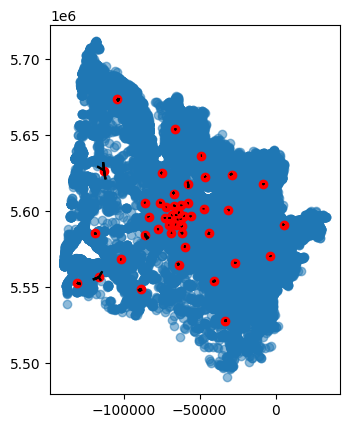

In [13]:
base = sm.road_nodes.plot(alpha=0.5)
sm.zones.plot(ax=base, color='red')
gpd.GeoDataFrame(sm.zone_to_road, geometry='geometry', crs='EPSG:3857').plot(ax=base, color='black')

In [14]:
od_set = {(f, t) for f in sm.zones.reset_index()['index'].values.tolist() for t in sm.zones.reset_index()['index'].values.tolist()}

In [15]:
sm.step_road_pathfinder(method='aon', od_set=od_set)

self.volumes does not exist. od generated with self.zones, od_set


In [16]:
sm.analysis_car_los()

In [17]:
sm.analysis_car_length()

In [18]:
distances = sm.car_los[['origin', 'destination', 'length']].copy().rename(columns={'length': 'distance'})
distances = distances.loc[distances['origin'] != distances['destination']]
distances['origin'] = distances['origin'].apply(lambda x: x.replace('DTIR_', '')).map(int)
distances['destination'] = distances['destination'].apply(lambda x: x.replace('DTIR_', '')).map(int)

In [19]:
intra_zone_distances['distance'] = intra_zone_distances.area** 0.5 * INTRA_AREA_TO_DISTANCE_FACTOR
intra_zone_distances['origin'] = intra_zone_distances['NUM_DTIR'].copy()
intra_zone_distances['destination'] = intra_zone_distances['NUM_DTIR'].copy()
intra_zone_distances = intra_zone_distances[['origin', 'destination', 'distance']]

In [20]:
distances_all = pd.concat([distances, intra_zone_distances])
distances_all_rev = distances_all.rename(columns={'origin': 'destination', 'destination': 'origin'})

distances_all = pd.concat([distances_all.loc[distances_all['distance'] != 0], distances_all_rev]).drop_duplicates(subset=['origin', 'destination'], keep='first')

In [21]:
deplacements_light = deplacements_light.merge(distances_all, left_on=['zone_from', 'zone_to'], right_on=['origin', 'destination'])

In [22]:
trajets['household_id'] = trajets['TP2'].astype(str) + '_' + trajets['ECH'].astype(str)
trajets_light = trajets[['household_id', 'PER', 'NDEP', 'T1']].rename(columns={
        'PER': 'commuter_id',
        'NDEP': 'journey_id',
        'T1': 'trip_id' 
    }).copy()

In [23]:
trajets_light = deplacements_light.merge(trajets_light, on=['household_id', 'commuter_id', 'journey_id'])

In [24]:
### Filtre sur l'heure de pointe matin (7h - 10h)
trajets_light = trajets_light.loc[(trajets_light['departure_time'] >= 7*3600) & (trajets_light['arrival_time'] < 10*3600)]

In [25]:
trajets_light['duration'] = (trajets_light['arrival_time'] - trajets_light['departure_time'])/60

In [26]:
trajets_light['distance'].describe()

count      3382.000000
mean      19310.267827
std       15250.173928
min        2725.794820
25%        8220.864315
50%       14109.684847
75%       25819.686584
max      130617.325362
Name: distance, dtype: float64

In [31]:
trajets_light.to_csv('../../inputs/EMT/distance_dist.csv')